# ML Modelling: Assignment 2 
- Big Data - 2025
- Juan Sebastian Vargas Torres

## Imports

In [0]:
# === Core Data Science Libraries ===
import pandas as pd

# === Visualization Libraries ===
import altair as alt
import matplotlib.pyplot as plt
import seaborn as sns

# === Statistical Libraries ===
import pingouin as pg

# === PySpark Libraries ===
import pyspark.sql.functions as F
from pyspark.sql import DataFrame
from pyspark.sql.types import (
    BooleanType, DoubleType, FloatType, IntegerType, LongType, ShortType, 
    StringType, StructField, StructType
)

# === Scikit-learn Libraries ===
from sklearn.linear_model import Lasso
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from pyspark.sql import DataFrame as SparkDataFrame

# === Standard Python Libraries ===
from typing import List

# === Library Configurations ===
# This line should be run after the imports to set up the display environment.
alt.renderers.enable('default')

Exception ignored on calling ctypes callback function: <function _ThreadpoolInfo._find_modules_with_dl_iterate_phdr.<locals>.match_module_callback at 0xff5727790360>
Traceback (most recent call last):
  File "/databricks/python/lib/python3.12/site-packages/threadpoolctl.py", line 400, in match_module_callback
    self._make_module_from_path(filepath)
  File "/databricks/python/lib/python3.12/site-packages/threadpoolctl.py", line 515, in _make_module_from_path
    module = module_class(filepath, prefix, user_api, internal_api)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/databricks/python/lib/python3.12/site-packages/threadpoolctl.py", line 606, in __init__
    self.version = self.get_version()
                   ^^^^^^^^^^^^^^^^^^
  File "/databricks/python/lib/python3.12/site-packages/threadpoolctl.py", line 646, in get_version
    config = get_config().split()
             ^^^^^^^^^^^^^^^^^^
AttributeError: 'NoneType' object has no attribute 'split'


RendererRegistry.enable('default')

## Utils

In [0]:
def plot_correlation_matrix(spark_df: DataFrame, sample_fraction: float = 0.1):
    """
    Calculates and plots a correlation matrix by converting a sample of a
    Spark DataFrame to a Pandas DataFrame.

    Args:
        spark_df (DataFrame): The input Spark DataFrame.
        sample_fraction (float): The fraction of data to sample. 
                                 Set to 1.0 to use the full dataset (DANGEROUS on large data).
    """
    # 1. Identify numerical columns
    numerical_types = [DoubleType, IntegerType, FloatType, LongType, ShortType]
    numerical_cols = [f.name for f in spark_df.schema.fields if isinstance(f.dataType, tuple(numerical_types))]
    
    if not numerical_cols:
        print("No numerical columns found in the DataFrame.")
        return

    print(f"Sampling {sample_fraction*100}% of data for correlation on columns: {numerical_cols}")
    
    # 2. Sample the data and convert to Pandas
    # This is the key step that is different from the ML approach
    try:
        df_sample = spark_df.select(numerical_cols).sample(fraction=sample_fraction, seed=42)
        corr_matrix_pd = df_sample.toPandas().corr()
    except Exception as e:
        print(f"An error occurred, likely an OutOfMemoryError. The dataset might be too large.")
        print(f"Try using a smaller 'sample_fraction'. Error: {e}")
        return

    # 3. Plot the heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix_pd, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title(f'Correlation Matrix (Sampled at {sample_fraction*100}%)', fontsize=16)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [0]:
def calculate_welchs_anova(spark_df: SparkDataFrame, 
                                 target_col: str, 
                                 sample_fraction: float = 0.1):
    """
    Calculates Welch's ANOVA on a sample of a Spark DataFrame.

    This function takes a sample of the Spark DataFrame, converts it to a Pandas
    DataFrame, and then calculates Welch's ANOVA for each categorical variable
    against the continuous target variable.

    Args:
        spark_df (SparkDataFrame): The input Spark DataFrame.
        target_col (str): The name of the continuous target variable.
        sample_fraction (float): The fraction of data to sample (e.g., 0.1 for 10%).
                                 This is crucial to prevent memory errors.

    Returns:
        pd.DataFrame: A DataFrame with the F-statistic and p-value for each 
                      categorical variable, sorted by the F-statistic.
    """
    # 1. Identify categorical columns from the Spark schema
    categorical_types = [StringType, BooleanType]
    categorical_cols = [f.name for f in spark_df.schema.fields if isinstance(f.dataType, tuple(categorical_types))]
    
    if target_col in categorical_cols:
        categorical_cols.remove(target_col)

    if not categorical_cols:
        print("No categorical columns found to perform the test.")
        return pd.DataFrame()

    # Define all columns needed for the analysis to minimize data transfer
    cols_to_select = [target_col] + categorical_cols
    
    print(f"Analyzing a {sample_fraction*100}% sample of the data...")

    try:
        # 2. Sample the Spark DataFrame and convert the sample to Pandas
        # This is a critical step. An overly large sample can cause an OutOfMemoryError.
        pd_sample_df = spark_df.select(cols_to_select).sample(
            fraction=sample_fraction, 
            seed=42
        ).toPandas()
    except Exception as e:
        print(f"An error occurred converting the Spark sample to Pandas, likely an OutOfMemoryError.")
        print(f"Try using a smaller 'sample_fraction'. Error: {e}")
        return pd.DataFrame()

    # 3. Calculate Welch's ANOVA for each categorical column using the Pandas sample
    results = []
    for col in categorical_cols:
        try:
            anova_result = pg.welch_anova(data=pd_sample_df, dv=target_col, between=col)
            results.append({
                'Categorical Variable': col,
                'F-Statistic': anova_result['F'][0],
                'p-value': anova_result['p-unc'][0]
            })
        except Exception as e:
            print(f"Could not perform ANOVA for '{col}'. Skipping. Reason: {e}")

    if not results:
        print("ANOVA could not be calculated for any categorical variable.")
        return pd.DataFrame()
        
    # 4. Create and sort the final results DataFrame
    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by='F-Statistic', ascending=False).reset_index(drop=True)
    
    return results_df

In [0]:
def one_hot_encode_spark(df, cols_to_encode):
    """
    Manually one-hot encodes specified categorical columns in a Spark DataFrame
    without using the ML library.

    Args:
        df (SparkDataFrame): The input Spark DataFrame.
        cols_to_encode (list): A list of column names to encode.

    Returns:
        SparkDataFrame: The DataFrame with new one-hot encoded columns.
    """
    transformed_df = df
    for col_name in cols_to_encode:
        categories = [
            row[0] for row in transformed_df.select(col_name).distinct().collect()
        ]
        
        print(f"Encoding {len(categories)} categories for column '{col_name}'...")
        for category in categories:
            new_col_name = f"{col_name}_{category.replace(' ', '_')}"
            transformed_df = transformed_df.withColumn(
                new_col_name,
                F.when(F.col(col_name) == category, 1).otherwise(0)
            )
    transformed_df = transformed_df.drop(*cols_to_encode)
    return transformed_df

In [0]:
def calculate_rmse(actual_df: DataFrame, predicted_df: DataFrame, actual_col: str, predicted_col: str):
    """
    Calculates the Root Mean Squared Error (RMSE) between two Spark DataFrames.

    Args:
        actual_df (DataFrame): DataFrame containing the actual target values.
        predicted_df (DataFrame): DataFrame containing the predicted values.
        actual_col (str): The name of the column with actual values.
        predicted_col (str): The name of the column with predicted values.

    Returns:
        float: The calculated RMSE value.
    """
    # 1. Add a unique ID to each DataFrame to ensure rows are matched correctly
    actual_with_id = actual_df.withColumn("row_id", F.monotonically_increasing_id())
    predicted_with_id = predicted_df.withColumn("row_id", F.monotonically_increasing_id())

    # 2. Join the actual and predicted values on the unique ID
    joined_df = actual_with_id.join(predicted_with_id, on="row_id").drop("row_id")

    # 3. Calculate the squared error, then the mean, then the square root (RMSE)
    rmse_df = joined_df.withColumn("squared_error", F.pow(F.col(actual_col) - F.col(predicted_col), 2)) \
                       .agg(F.sqrt(F.mean("squared_error")).alias("rmse"))
    
    # 4. Collect the single RMSE value and return it
    rmse_value = rmse_df.collect()[0]["rmse"]
    return rmse_value

In [0]:
def manual_standard_scaler(df: DataFrame, params: dict, cols: list) -> DataFrame:
    """
    Applies standard scaling to a DataFrame using pre-computed parameters.
    """
    scaled_df = df
    for col_name in cols:
        mean_val = params[f"{col_name}_mean"]
        std_val = params[f"{col_name}_std"]
                
        scaled_df = scaled_df.withColumn(
            col_name, 
            (F.col(col_name) - mean_val) / std_val
        )
    return scaled_df

In [0]:
def plot_actual_vs_predicted(actual_values: pd.Series, predicted_values: pd.Series, title: str = ''):
    """
    Creates a scatter plot of actual vs. predicted values and overlays a 
    scatter plot of actual vs. actual values to show a perfect prediction line.

    Args:
        actual_values (pd.Series): A pandas Series of the true target values.
        predicted_values (pd.Series): A pandas Series of the model's predicted values.
        title (str): An optional title for the chart.
    """
    # 1. Create the scatter plot of actual vs. predicted (your model's performance)
    plt.figure(figsize=(8, 8))
    plt.scatter(predicted_values, predicted_values, alpha=0.5, label='Prediction')

    # 2. Create the perfect prediction plot by plotting actual values against themselves
    # This directly plots every single actual value in a perfect diagonal.
    plt.scatter(actual_values, actual_values, color='red', alpha=0.5, s=10, label='Perfect')

    # 3. Add labels, title, and legend
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.title(f'Actual vs. Predicted Values {title}')
    plt.grid(True)
    plt.legend()
    
    # 4. Ensure the axes are scaled equally for a true diagonal line
    plt.axis('equal')
    
    # 5. Display the plot
    plt.show()

## Reading Data

In [0]:
catalog = "workspace"
source_schema  = "bde_silver"
taxis_table_name = 'taxis_trips'
gold_schema = "bde_gold"
TAXIS_TABLE_PATH = f"{catalog}.{source_schema}.{taxis_table_name}"

In [0]:
full_taxis_trips_data = spark.table(TAXIS_TABLE_PATH)
START_RANGE_DATE = '2024-01-01'
taxis_trips_data = full_taxis_trips_data.filter(F.col("pickup_datetime")>=START_RANGE_DATE)
taxis_trips_data = taxis_trips_data.drop('Fare_amount','Tolls_amount','VendorID','RatecodeID')
taxis_trips_data= taxis_trips_data.filter(F.col('pickup_borough')!='Unknown')
taxis_trips_data = taxis_trips_data.filter(F.col('dropoff_borough')!='Unknown')

In [0]:
taxis_trips_data.count()

34177219

## Feature Preparation for Modelling

In [0]:
taxis_trips_data.limit(5).display()

pickup_datetime,dropoff_datetime,passenger_count,trip_distance,store_and_fwd_flag,payment_type,extra,mta_tax,tip_amount,total_amount,duration_in_hours,duration_in_minutes,speed,trip_type,taxi_type,pickup_borough,pickup_zone,dropoff_borough,dropoff_zone
2024-01-03T10:00:04.000Z,2024-01-03T11:08:22.000Z,1.0,21.6,N,1.0,0.0,0.5,18.46,110.75,1.14,68.3,18.95,0.0,yellow,Queens,JFK Airport,Bronx,Kingsbridge Heights
2024-01-01T00:01:34.000Z,2024-01-01T00:05:41.000Z,1.0,0.71,N,2.0,1.0,0.5,0.0,11.5,0.07,4.12,10.14,0.0,yellow,Manhattan,Union Sq,Manhattan,East Chelsea
2024-01-01T00:01:58.000Z,2024-01-01T00:10:04.000Z,3.0,1.7,N,1.0,1.0,0.5,2.36,18.06,0.14,8.1,12.14,0.0,yellow,Manhattan,Union Sq,Manhattan,Little Italy/NoLiTa
2024-01-01T00:57:55.000Z,2024-01-01T01:17:43.000Z,1.0,1.72,N,2.0,1.0,0.5,0.0,22.7,0.33,19.8,5.21,0.0,yellow,Manhattan,Penn Station/Madison Sq West,Manhattan,East Village
2024-01-01T00:03:00.000Z,2024-01-01T00:09:36.000Z,1.0,1.8,N,1.0,3.5,0.5,3.75,18.75,0.11,6.6,16.36,0.0,yellow,Manhattan,Lenox Hill East,Manhattan,Upper East Side North


Sampling 20.0% of data for correlation on columns: ['passenger_count', 'trip_distance', 'payment_type', 'extra', 'mta_tax', 'tip_amount', 'total_amount', 'duration_in_hours', 'duration_in_minutes', 'speed', 'trip_type']


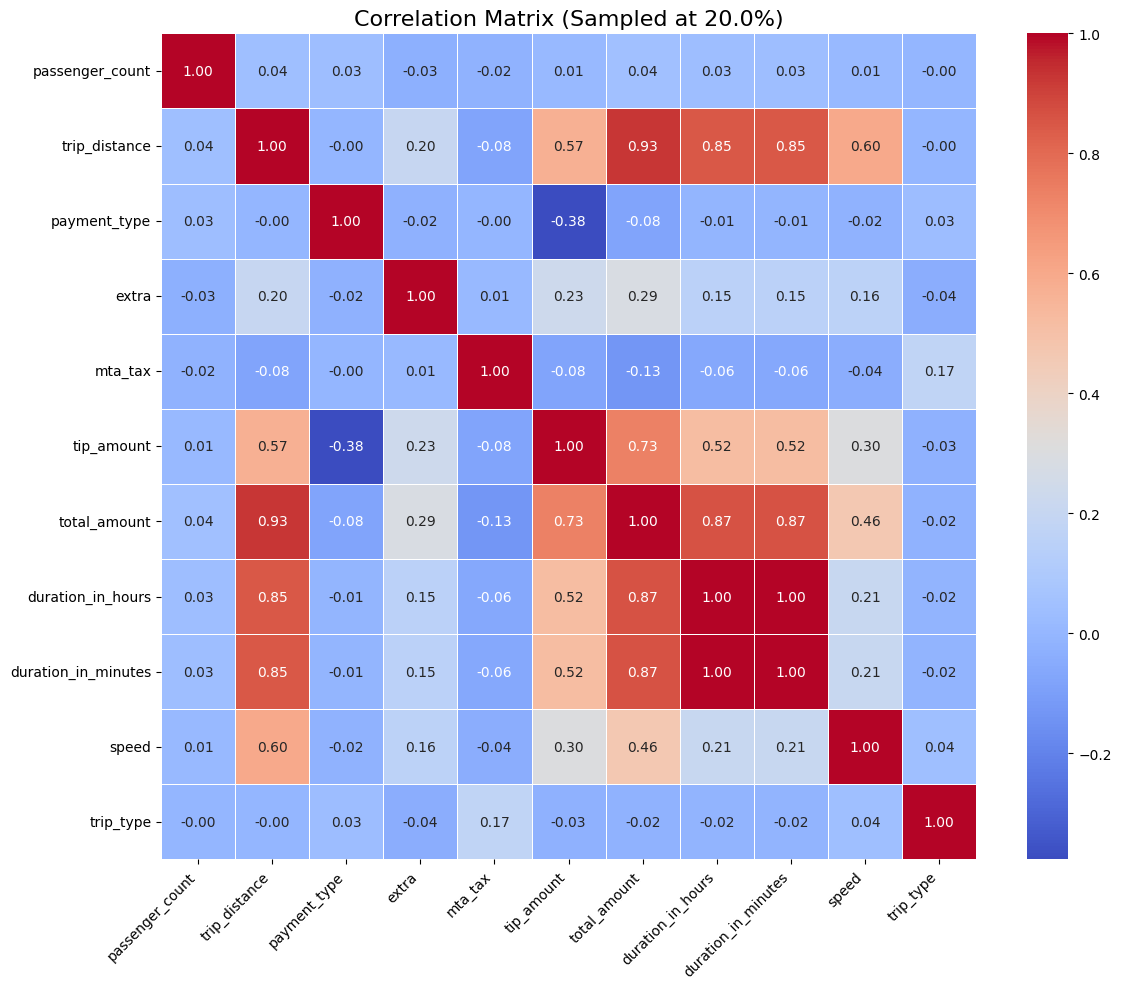

In [0]:
plot_correlation_matrix(taxis_trips_data, sample_fraction=0.2)

In [0]:
calculate_welchs_anova(spark_df=taxis_trips_data, target_col='total_amount', sample_fraction=0.1)

Analyzing a 10.0% sample of the data...


,Categorical Variable,F-Statistic,p-value
0,pickup_borough,139053.129046,7.065875e-185
1,dropoff_borough,74128.585616,0.000000e+00
2,pickup_zone,5027.362395,0.000000e+00
3,dropoff_zone,3320.549643,0.000000e+00
4,taxi_type,2955.504265,0.000000e+00
5,store_and_fwd_flag,17.045502,3.669762e-05


### Removing high correlated columns

In [0]:
drop_correlated_columns = ['duration_in_hours','duration_in_minutes','speed']
taxis_trips_data = taxis_trips_data.drop(*drop_correlated_columns)

### Remove unneccesary categorical variables

In [0]:
drop_categorical_columns = ['pickup_zone','dropoff_zone','store_and_fwd_flag']
taxis_trips_data = taxis_trips_data.drop(*drop_categorical_columns)

### Join with taxis_colour_pickup_dropoff_stats view

In [0]:
taxis_colour_pickup_dropoff_stats = spark.sql(f"""
SELECT *
FROM {catalog}.{gold_schema}.taxis_colour_pickup_dropoff_stats          
""")

In [0]:
trips_with_keys = taxis_trips_data.withColumn("month", F.month(F.col("pickup_datetime"))) \
                                  .withColumn("weekday", F.date_format(F.col("pickup_datetime"), "EEEE")) \
                                  .withColumn("hour", F.hour(F.col("pickup_datetime")))

In [0]:
stats_to_join = taxis_colour_pickup_dropoff_stats.select(
    F.col("taxi_type"),
    F.col("pickup_borough"),
    F.col("dropoff_borough"),
    F.col("`month(pickup_datetime)`").alias("month"),
    F.col("weekday"),
    F.col("`hour(pickup_datetime)`").alias("hour"),
    F.col("avg_amount")
)

In [0]:
join_keys = [
    "taxi_type", 
    "pickup_borough", 
    "dropoff_borough", 
    "month", 
    "weekday", 
    "hour"
]

In [0]:
taxis_trips_data = trips_with_keys.join(stats_to_join, on=join_keys, how="left")

In [0]:
taxis_trips_data.limit(5).display()

taxi_type,pickup_borough,dropoff_borough,month,weekday,hour,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,payment_type,extra,mta_tax,tip_amount,total_amount,trip_type,avg_amount
yellow,Manhattan,Manhattan,1,Monday,0,2024-01-01T00:01:34.000Z,2024-01-01T00:05:41.000Z,1.0,0.71,2.0,1.0,0.5,0.0,11.5,0.0,12.51
yellow,Manhattan,Manhattan,1,Monday,0,2024-01-01T00:01:58.000Z,2024-01-01T00:10:04.000Z,3.0,1.7,1.0,1.0,0.5,2.36,18.06,0.0,12.51
yellow,Manhattan,Manhattan,1,Monday,0,2024-01-01T00:57:55.000Z,2024-01-01T01:17:43.000Z,1.0,1.72,2.0,1.0,0.5,0.0,22.7,0.0,12.51
yellow,Manhattan,Manhattan,1,Monday,0,2024-01-01T00:03:00.000Z,2024-01-01T00:09:36.000Z,1.0,1.8,1.0,3.5,0.5,3.75,18.75,0.0,12.51
yellow,Queens,Bronx,1,Wednesday,10,2024-01-03T10:00:04.000Z,2024-01-03T11:08:22.000Z,1.0,21.6,1.0,0.0,0.5,18.46,110.75,0.0,54.28


In [0]:
columns_top_drop = ['month','weekday','hour']
taxis_trips_data = taxis_trips_data.drop(*columns_top_drop)

### Categorical On-hot-encoding

In [0]:
taxis_trips_data_to_model = taxis_trips_data

In [0]:
categorical_cols = [
    field.name for field in taxis_trips_data_to_model.schema.fields
    if isinstance(field.dataType, StringType) and field.name not in ['pickup_borough','dropoff_borough']
]
categorical_cols

['taxi_type']

In [0]:

taxis_trips_data_to_model = one_hot_encode_spark(taxis_trips_data_to_model, categorical_cols)
taxis_trips_data_to_model.display()

Encoding 2 categories for column 'taxi_type'...


pickup_borough,dropoff_borough,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,payment_type,extra,mta_tax,tip_amount,total_amount,trip_type,avg_amount,taxi_type_yellow,taxi_type_green
Manhattan,Staten Island,2024-01-01T01:28:14.000Z,2024-01-01T02:31:50.000Z,1.0,21.15,1.0,1.0,0.5,46.25,231.25,0.0,98.16,1,0
Manhattan,Staten Island,2024-01-01T01:07:50.000Z,2024-01-01T01:56:32.000Z,2.0,19.08,2.0,1.0,0.5,0.0,106.52,0.0,98.16,1,0
Queens,Manhattan,2024-01-01T00:41:47.000Z,2024-01-01T01:28:37.000Z,1.0,17.5,1.0,4.25,0.5,16.5,99.19,0.0,34.92,1,0
Queens,Manhattan,2024-01-01T00:27:15.000Z,2024-01-01T01:15:36.000Z,2.0,19.54,1.0,0.0,0.5,5.0,87.69,0.0,34.92,1,0
Queens,Manhattan,2024-01-01T00:19:07.000Z,2024-01-01T01:06:16.000Z,1.0,18.6,1.0,0.0,0.5,20.23,102.92,0.0,34.92,1,0
Queens,Manhattan,2024-01-01T00:12:46.000Z,2024-01-01T00:38:49.000Z,1.0,9.77,1.0,6.0,0.5,10.96,71.85,0.0,34.92,1,0
Queens,Manhattan,2024-01-01T00:28:53.000Z,2024-01-01T00:57:32.000Z,1.0,9.33,1.0,6.0,0.5,12.18,73.07,0.0,34.92,1,0
Queens,Manhattan,2024-01-01T00:14:32.000Z,2024-01-01T00:46:33.000Z,2.0,11.25,1.0,6.0,0.5,10.0,79.99,0.0,34.92,1,0
Queens,Manhattan,2024-01-01T00:58:58.000Z,2024-01-01T01:19:25.000Z,3.0,4.0,1.0,3.5,0.5,5.5,33.1,0.0,34.92,1,0
Queens,Manhattan,2024-01-01T00:06:40.000Z,2024-01-01T00:34:26.000Z,1.0,9.85,1.0,6.0,0.5,9.96,65.31,0.0,34.92,1,0


### Split data train-val-test

In [0]:
taxis_trips_data_to_model = taxis_trips_data_to_model.drop('pickup_borough','dropoff_borough')

In [0]:
train_start_date = START_RANGE_DATE
train_end_date = "2024-07-31"
val_start_date = "2024-08-01"
val_end_date = "2024-09-30"

sample_fraction = 0.3
seed = 42

train_df = taxis_trips_data_to_model.where(
    (F.col("pickup_datetime") >= train_start_date) & 
    (F.col("pickup_datetime") <= train_end_date)
).sample(fraction=sample_fraction, seed=seed)


val_df = taxis_trips_data_to_model.where(
    (F.col("pickup_datetime") >= val_start_date) & 
    (F.col("pickup_datetime") <= val_end_date)
).sample(fraction=sample_fraction, seed=seed)

test_df = taxis_trips_data_to_model.where(
    F.col("pickup_datetime") > val_end_date
).sample(fraction=sample_fraction, seed=seed)

print("Data splitting and sampling complete.")
print(f"Sampled training set rows: {train_df.count()}")
print(f"Validation set rows: {val_df.count()}")
print(f"Test set rows: {test_df.count()}")

Data splitting and sampling complete.
Sampled training set rows: 5820399
Validation set rows: 1590863
Test set rows: 2813051


In [0]:
target_col = "total_amount"
cols_to_drop = ["pickup_datetime", "dropoff_datetime"]

# --- Split the Training Set ---
y_train = train_df.select(target_col)
X_train = train_df.drop(target_col, *cols_to_drop)


# --- Split the Validation Set ---
y_val = val_df.select(target_col)
X_val = val_df.drop(target_col, *cols_to_drop)


# --- Split the Test Set ---
y_test = test_df.select(target_col)
X_test = test_df.drop(target_col, *cols_to_drop)

In [0]:
perfect_values_train = y_train.toPandas()['total_amount']
perfect_values_val = y_val.toPandas()['total_amount']
perfect_values_test = y_test.toPandas()['total_amount']

## Baseline Model

Build at least two different ML models(two different algorithms) to predict the Total amount of a trip:
- Use the answer of Part 2 Q3c (average total amount per colour, pair of locations, month, day of week and hours) and calculate its RMSE.
- You can use all the dataset except October, November and December 2024 to train and validate your models and use the RMSE score to assess your models.
- Choose your best model and explain why you choose it (processing time, complexity, accuracy, etc).
- Using your best model, predict the October, November and December 2024 trips and calculate the RMSE on your predictions. Does your model beat the baseline model?

In [0]:
y_train_prediction_baseline = X_train.select(F.col('avg_amount').alias('predicted_amount'))
y_val_prediction_baseline = X_val.select(F.col('avg_amount').alias('predicted_amount'))


rmse_train = calculate_rmse(
    actual_df=y_train, 
    predicted_df=y_train_prediction_baseline,
    actual_col="total_amount",
    predicted_col="predicted_amount"
)

rmse_val = calculate_rmse(
    actual_df=y_val, 
    predicted_df=y_val_prediction_baseline,
    actual_col="total_amount",
    predicted_col="predicted_amount"
)

# 4. Print the results
print(f"Baseline Model RMSE on Training Set:   {rmse_train:.4f}")
print(f"Baseline Model RMSE on Validation Set: {rmse_val:.4f}")


Baseline Model RMSE on Training Set:   22.8606
Baseline Model RMSE on Validation Set: 30.5321


In [0]:
y_train_prediction_baseline_pandas = y_train_prediction_baseline.toPandas()['predicted_amount']

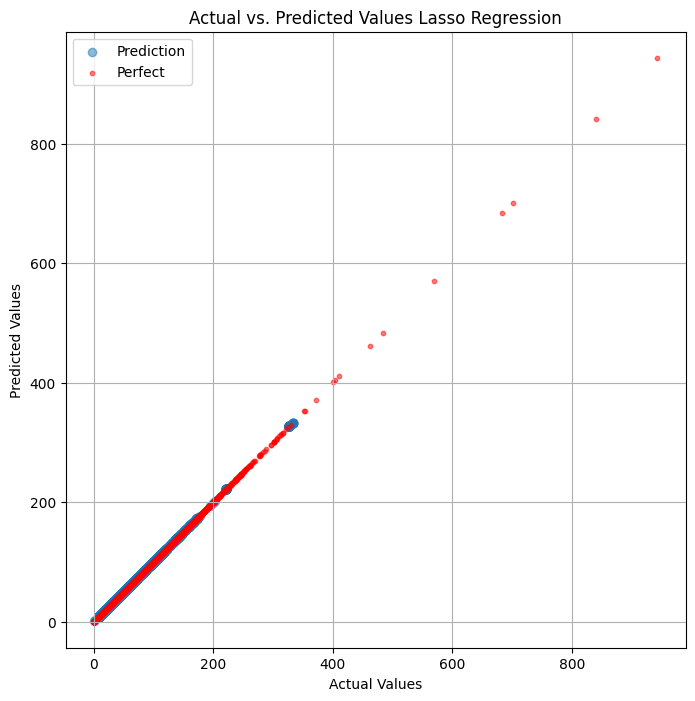

In [0]:
plot_actual_vs_predicted(perfect_values_train, y_train_prediction_baseline_pandas, title="Lasso Regression")

## Aditional Data Tranformations for modelling

In [0]:
X_train_modelling = X_train.drop("avg_amount")
X_val_modelling = X_val.drop("avg_amount")
X_test_modelling = X_test.drop("avg_amount")

## Model 1: Lasso

In [0]:
X_train_lasso = X_train_modelling
X_val_lasso = X_val_modelling
X_test_lasso = X_test_modelling

In [0]:
# --- Step 1: Identify Numerical Columns to Scale ---
numerical_types = [DoubleType, IntegerType, FloatType, LongType, ShortType]
numerical_cols = [
    f.name for f in X_train_lasso.schema.fields 
    if isinstance(f.dataType, tuple(numerical_types))
]
print(f"Columns to be scaled: {numerical_cols}")

# --- Step 2: Calculate Mean and StdDev from the Training Set ONLY ---
agg_expressions = []
for col_name in numerical_cols:
    agg_expressions.append(F.mean(col_name).alias(f"{col_name}_mean"))
    agg_expressions.append(F.stddev(col_name).alias(f"{col_name}_std"))

scaling_params_row = X_train_lasso.agg(*agg_expressions).collect()[0]
scaling_params = scaling_params_row.asDict()

Columns to be scaled: ['passenger_count', 'trip_distance', 'payment_type', 'extra', 'mta_tax', 'tip_amount', 'trip_type', 'taxi_type_yellow', 'taxi_type_green']


In [0]:
X_train_lasso = manual_standard_scaler(X_train_lasso, scaling_params, numerical_cols)
X_val_lasso = manual_standard_scaler(X_val_lasso, scaling_params, numerical_cols)
X_test_lasso = manual_standard_scaler(X_test_lasso, scaling_params, numerical_cols)

In [0]:
X_train_lasso = X_train_lasso.toPandas()
y_train_lasso = y_train.toPandas()

X_val_lasso = X_val_lasso.toPandas()
y_val_lasso = y_val.toPandas()

X_test_lasso = X_test_lasso.toPandas()
y_test_lasso = y_test.toPandas()

In [0]:
ls_regressor = Lasso()

In [0]:
param_grid_lasso = {
    'alpha': [0, 0.1, 0.5, 0.75, 1]
}

grid_search_lasso = GridSearchCV(
    estimator=ls_regressor,
    param_grid=param_grid_lasso,
    cv=3,
    verbose=1,
    n_jobs=-1
)

grid_search_lasso.fit(X_train_lasso, y_train_lasso)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


/databricks/python/lib/python3.12/site-packages/sklearn/base.py:1474: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/databricks/python/lib/python3.12/site-packages/sklearn/base.py:1474: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/databricks/python/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:678: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/databricks/python/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:678: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/databricks/python/lib/python3.1

GridSearchCV(cv=3, estimator=Lasso(), n_jobs=-1,
             param_grid={'alpha': [0, 0.1, 0.5, 0.75, 1]}, verbose=1)

In [0]:
print("--- Lasso Grid Search Results ---")
print(f"Best Parameters: {grid_search_lasso.best_params_}")

--- Lasso Grid Search Results ---
Best Parameters: {'alpha': 0.5}


In [0]:
best_ls_regressor_1 = Lasso(alpha=0.1)
best_ls_regressor_1.fit(X_train_lasso, y_train_lasso)

predictions_train_lasso_1 = best_ls_regressor_1.predict(X_train_lasso)
root_mean_squared_error_train_lasso_1 = root_mean_squared_error(y_train_lasso, predictions_train_lasso_1)
print(f"Lasso Model RMSE on Training Set: {root_mean_squared_error_train_lasso_1}")

predictions_val_lasso_2 = best_ls_regressor_1.predict(X_val_lasso)
root_mean_squared_error_val_lasso_1 = root_mean_squared_error(y_val_lasso, predictions_val_lasso_2)
print(f"Lasso Model RMSE on Validation Set: {root_mean_squared_error_val_lasso_1}")

print(f"The Difference in RMSE between Training and Validation Sets is {root_mean_squared_error_val_lasso_1-root_mean_squared_error_train_lasso_1}")

Lasso Model RMSE on Training Set: 4.536434872649311
Lasso Model RMSE on Validation Set: 5.1084739526080325
The Difference in RMSE between Training and Validation Sets is 0.5720390799587216


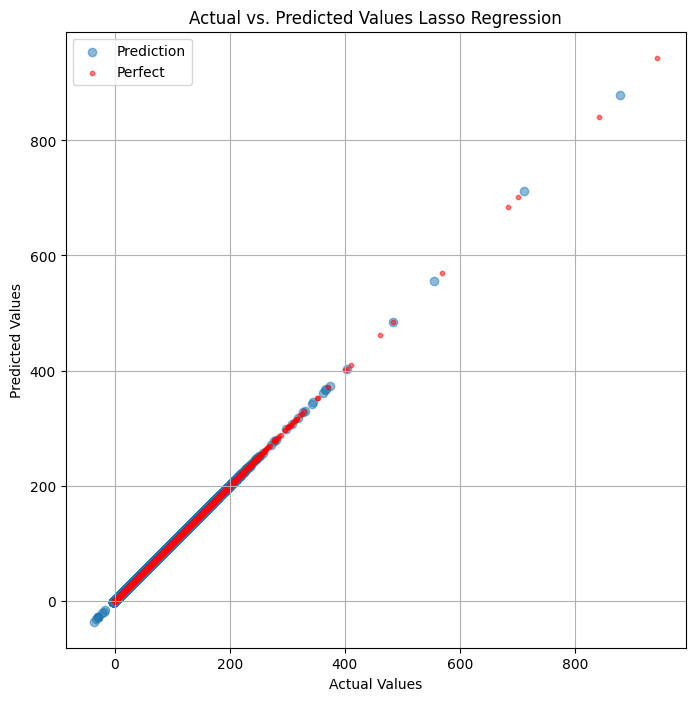

In [0]:
plot_actual_vs_predicted(perfect_values_train, predictions_train_lasso_1, title="Lasso Regression")

In [0]:
best_ls_regressor_2 = Lasso(alpha=0.25)
best_ls_regressor_2.fit(X_train_lasso, y_train_lasso)

predictions_train_lasso_2 = best_ls_regressor_2.predict(X_train_lasso)
root_mean_squared_error_train_lasso_2 = root_mean_squared_error(y_train_lasso, predictions_train_lasso_2)
print(f"Lasso Model RMSE on Training Set: {root_mean_squared_error_train_lasso_2}")

predictions_val_lasso_2 = best_ls_regressor_2.predict(X_val_lasso)
root_mean_squared_error_val_lasso_2 = root_mean_squared_error(y_val_lasso, predictions_val_lasso_2)
print(f"Lasso Model RMSE on Validation Set: {root_mean_squared_error_val_lasso_2}")

print(f"The Difference in RMSE between Training and Validation Sets is {root_mean_squared_error_val_lasso_2-root_mean_squared_error_train_lasso_2}")

Lasso Model RMSE on Training Set: 4.5647317771448
Lasso Model RMSE on Validation Set: 5.145556304141036
The Difference in RMSE between Training and Validation Sets is 0.5808245269962358


In [0]:
best_ls_regressor_3 = Lasso(alpha=0.5)
best_ls_regressor_3.fit(X_train_lasso, y_train_lasso)

predictions_train_lasso_3 = best_ls_regressor_3.predict(X_train_lasso)
root_mean_squared_error_train_lasso_3 = root_mean_squared_error(y_train_lasso, predictions_train_lasso_3)
print(f"Lasso Model RMSE on Training Set: {root_mean_squared_error_train_lasso_3}")

predictions_val_lasso_3 = best_ls_regressor_3.predict(X_val_lasso)
root_mean_squared_error_val_lasso_3 = root_mean_squared_error(y_val_lasso, predictions_val_lasso_3)
print(f"Lasso Model RMSE on Validation Set: {root_mean_squared_error_val_lasso_3}")

print(f"The Difference in RMSE between Training and Validation Sets is {root_mean_squared_error_val_lasso_3-root_mean_squared_error_train_lasso_3}")

Lasso Model RMSE on Training Set: 4.657639961783454
Lasso Model RMSE on Validation Set: 5.25334999198365
The Difference in RMSE between Training and Validation Sets is 0.5957100302001956


## Model 2: Decision Tree Regresor

In [0]:
X_train_dt = X_train_modelling
X_val_dt = X_val_modelling
X_test_dt = X_test_modelling

In [0]:
X_train_dt = X_train_dt.toPandas()
y_train_dt = y_train.toPandas()

X_val_dt = X_val_dt.toPandas()
y_val_dt = y_val.toPandas()

X_test_dt = X_test_dt.toPandas()
y_test_dt = y_test.toPandas()

In [0]:
dt_regressor = DecisionTreeRegressor()

In [0]:
param_grid_tree = {
    'max_depth': [2, 10, 15,25,30],
    'min_samples_leaf': [2, 4,8]
}
grid_search_tree = GridSearchCV(
    estimator=dt_regressor,
    param_grid=param_grid_tree,
    cv=2,
    verbose=1,
    n_jobs=-1
)
grid_search_tree.fit(X_train_dt, y_train_dt)

Fitting 2 folds for each of 15 candidates, totalling 30 fits


GridSearchCV(cv=2, estimator=DecisionTreeRegressor(), n_jobs=-1,
             param_grid={'max_depth': [2, 10, 15, 25, 30],
                         'min_samples_leaf': [2, 4, 8]},
             verbose=1)

In [0]:
print("--- Tree Grid Search Results ---")
print(f"Best Parameters: {grid_search_tree.best_params_}")

--- Tree Grid Search Results ---
Best Parameters: {'max_depth': 25, 'min_samples_leaf': 8}


In [0]:
best_dt_regressor_1 = DecisionTreeRegressor(max_depth=25, min_samples_leaf=8)

best_dt_regressor_1.fit(X_train_dt, y_train_dt)

predictions_train_dt_1 = best_dt_regressor_1.predict(X_train_dt)
root_mean_squared_error_train_dt_1 = root_mean_squared_error(y_train_dt, predictions_train_dt_1)
print(f"DT Model RMSE on Training Set: {root_mean_squared_error_train_dt_1}")

predictions_val_dt_1 = best_dt_regressor_1.predict(X_val_dt)
root_mean_squared_error_val_dt_1 = root_mean_squared_error(y_val_dt, predictions_val_dt_1)
print(f"DT Model RMSE on Validation Set: {root_mean_squared_error_val_dt_1}")

print(f"Difference between RMSE on Training and Validation Sets: {root_mean_squared_error_val_dt_1 - root_mean_squared_error_train_dt_1}")

DT Model RMSE on Training Set: 2.9187951450647303
DT Model RMSE on Validation Set: 3.6580668633470657
Difference between RMSE on Training and Validation Sets: 0.7392717182823354


In [0]:
best_dt_regressor_2 = DecisionTreeRegressor(max_depth=15, min_samples_leaf=4)

best_dt_regressor_2.fit(X_train_dt, y_train_dt)

predictions_train_dt_2 = best_dt_regressor_2.predict(X_train_dt)
root_mean_squared_error_train_dt_2 = root_mean_squared_error(y_train_dt, predictions_train_dt_2)
print(f"DT Model RMSE on Training Set: {root_mean_squared_error_train_dt_2}")

predictions_val_dt_2 = best_dt_regressor_2.predict(X_val_dt)
root_mean_squared_error_val_dt_2 = root_mean_squared_error(y_val_dt, predictions_val_dt_2)
print(f"DT Model RMSE on Validation Set: {root_mean_squared_error_val_dt_2}")

print(f"Difference between RMSE on Training and Validation Sets: {root_mean_squared_error_val_dt_2 - root_mean_squared_error_train_dt_2}")

DT Model RMSE on Training Set: 3.1093597619915867
DT Model RMSE on Validation Set: 3.7636579672319974
Difference between RMSE on Training and Validation Sets: 0.6542982052404107


In [0]:
best_dt_regressor_3 = DecisionTreeRegressor(max_depth=8, min_samples_leaf=4)

best_dt_regressor_3.fit(X_train_dt, y_train_dt)

predictions_train_dt_3 = best_dt_regressor_3.predict(X_train_dt)
root_mean_squared_error_train_dt_3 = root_mean_squared_error(y_train_dt, predictions_train_dt_3)
print(f"DT Model RMSE on Training Set: {root_mean_squared_error_train_dt_3}")

predictions_val_dt_3 = best_dt_regressor_3.predict(X_val_dt)
root_mean_squared_error_val_dt_3 = root_mean_squared_error(y_val_dt, predictions_val_dt_3)
print(f"DT Model RMSE on Validation Set: {root_mean_squared_error_val_dt_3}")

print(f"Difference between RMSE on Training and Validation Sets: {root_mean_squared_error_val_dt_3 - root_mean_squared_error_train_dt_3}")

DT Model RMSE on Training Set: 3.720613421057712
DT Model RMSE on Validation Set: 4.203644408775012
Difference between RMSE on Training and Validation Sets: 0.4830309877172998


## Best Model Selection

In [0]:
best_model = best_dt_regressor_3

In [0]:
predictions_test = best_model.predict(X_test_dt)
root_mean_squared_error_test = root_mean_squared_error(y_test_dt, predictions_test)
print(f"Best Model RMSE on Test Set: {root_mean_squared_error_test}")

Best Model RMSE on Test Set: 4.255790208757949


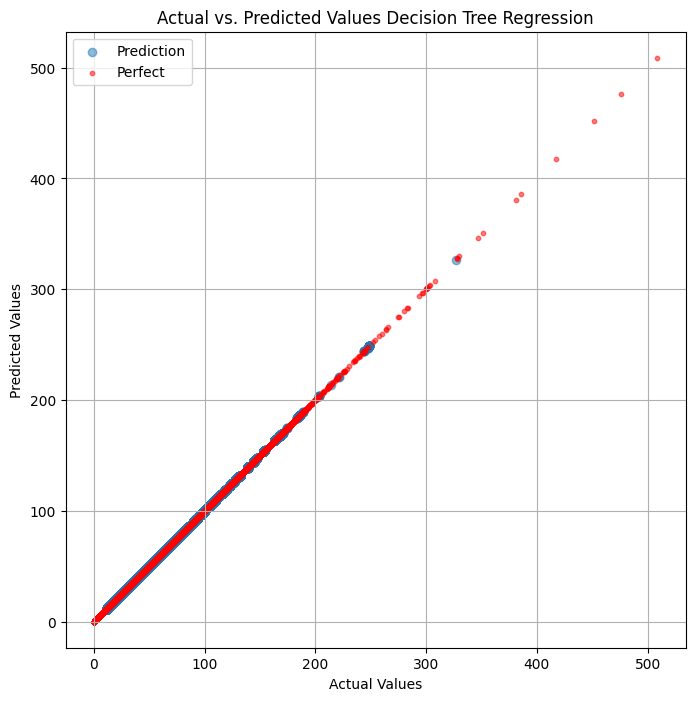

In [0]:
plot_actual_vs_predicted(perfect_values_test, predictions_test, title="Decision Tree Regression")